Code to parse the Asset Impact Data sent from Daan Koop to Scott on November 28, 2024. Data includes Texas, California and Pennsylvania and the well level.

In [1]:
# mount drive and define files
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# load in pandas, geopandas, shapely
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
!pip install xlsxwriter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 4.4 MB/s eta 0:00:00


In [3]:
# load in Asset Impact CSV, display header
goget_path = '/content/drive/Shareddrives/GEM Shared Drive/Programs/Oil & Gas Program/Global Oil and Gas Extraction Tracker (GOGET)/'
assetimpactdata = goget_path + 'Data sets & reports (O&G)/O&G global materials/Asset Impact Data/2025 Data/texas_2024.csv'

AIfull = pd.read_csv(assetimpactdata)
AIfull.head()

,country,state,county_name,year,well_no,well_name,field_no,field_name,lease_no,lease_name,...,resource_type,resource_type_detail,recovery_mechanism,field_terrain,oil_gravity,gas_gravity,oil_and_condensate_vol,gross_gas_vol,dry_gas_vol,ngl_vol
0,united_states,texas,HARRISON,2024.0,100001.0,NaN,9591300.0,BLOCKER (COTTON VALLEY),Gas_06_100001,NaN,...,Conventional,NaN,NaN,Onshore,53.1,0.635,0.000000,0.145124,0.145124,0.000000
1,united_states,texas,PANOLA,2024.0,100002.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100002,NaN,...,Conventional,NaN,NaN,Onshore,58.1,0.669,0.000000,0.703419,0.465588,0.003041
2,united_states,texas,PANOLA,2024.0,100003.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100003,NaN,...,Conventional,NaN,NaN,Onshore,60.4,0.706,0.000000,0.909622,0.602072,0.003932
3,united_states,texas,PANOLA,2024.0,100004.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100004,NaN,...,Conventional,NaN,NaN,Onshore,58.5,0.674,0.000000,0.424016,0.280653,0.001833
4,united_states,texas,PANOLA,2024.0,100005.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100005,NaN,...,Conventional,NaN,NaN,Onshore,60.0,0.683,0.000537,0.791541,0.700842,0.000000


In [10]:
# show entries for field_name = Newark, East (Barnett Shale)
NEWARK = AIfull[AIfull['field_name'] == 'NEWARK, EAST (BARNETT SHALE)']

# show unique field_terrain in NEWARK
NEWAR_offshore = NEWARK[NEWARK['field_terrain'] == 'Offshore']
NEWAR_offshore.columns

Index(['country', 'state', 'county_name', 'year', 'well_no', 'well_name',
       'field_no', 'field_name', 'lease_no', 'lease_name', 'formation_no',
       'formation_name', 'longitude', 'latitude', 'operator_no',
       'operator_name', 'owner_no', 'owner_name', 'ownership_perc',
       'resource_type', 'resource_type_detail', 'recovery_mechanism',
       'field_terrain', 'oil_gravity', 'gas_gravity', 'oil_and_condensate_vol',
       'gross_gas_vol', 'dry_gas_vol', 'ngl_vol'],
      dtype='object')

In [14]:
NEWAR_offshore.to_csv('/content/sample_data/texas_offshore.csv')

In [ ]:
# display columns, to get a sense of the data - comment out as this is not needed
AIfull.columns

Index(['country', 'state', 'county_name', 'year', 'well_no', 'well_name',
       'field_no', 'field_name', 'lease_no', 'lease_name', 'formation_no',
       'formation_name', 'longitude', 'latitude', 'operator_no',
       'operator_name', 'owner_no', 'owner_name', 'ownership_perc',
       'resource_type', 'resource_type_detail', 'recovery_mechanism',
       'field_terrain', 'oil_gravity', 'gas_gravity', 'oil_and_condensate_vol',
       'gross_gas_vol', 'dry_gas_vol', 'ngl_vol'],
      dtype='object')

In [ ]:
# rename oil and gas column dry_gas_vol to gas_dry_vol to match 2023 data
AIfull = AIfull.rename(columns={'dry_gas_vol': 'gas_dry_vol'})
AIfull = AIfull.rename(columns={'gross_gas_vol': 'gas_raw_vol'})

In [ ]:
# set data year filter to make data more manageable, per dan 2024 is modelled, but 2023 should not be.
yeardf = AIfull[AIfull['year'] == 2024]

In [ ]:
# check totals pre-group
print('oil total ' + str(yeardf['oil_and_condensate_vol'].sum()))
print('condensate total ' + str(yeardf['oil_and_condensate_vol'].sum())) # note change from 2024 data, they combined oil and condensate
print('gas_raw_vol total ' + str(yeardf['gas_raw_vol'].sum()))
print('gas_dry_vol total ' + str(yeardf['gas_dry_vol'].sum()))
print('ngl_vol total ' + str(yeardf['ngl_vol'].sum()))

oil total 2062.9972599999974
condensate total 2062.9972599999974
gas_raw_vol total 374899.2217922962
gas_dry_vol total 288552.26413919014
ngl_vol total 824.2709187519855


In [ ]:
# check totals by state pre-group, per dan: gas_dry_vol represents the dry gas volume, gas_raw_vol the gross gas production. For PA and CA, we haven’t modelled dry gas yet
raw_state_totals = yeardf.groupby('state')[['oil_and_condensate_vol', 'gas_raw_vol', 'gas_dry_vol', 'ngl_vol',]].sum().reset_index() # Changed tuple to list

# Ensure 'state' is a column after groupby
# The 'state' column might have become the index after the groupby operation
# reset_index() will make it a column again
raw_state_totals = raw_state_totals.reset_index()

raw_state_totals

,index,state,oil_and_condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol
0,0,texas,2062.99726,374899.221792,288552.264139,824.270919


In [ ]:
# define EIA totals to compare to
EIA_State_Totals = {
    'texas': {'EIA_liquids_vol':2011.52, 'EIA_gas_vol':326403.45},
    'pennsylvania': {'EIA_liquids_vol':4.82, 'EIA_gas_vol':214990.16},
    'california':{'EIA_liquids_vol':0, 'EIA_gas_vol':3701.09}
}

# Convert EIA_State_Totals to a DataFrame with 'state' as the index
EIA_State_Totals = pd.DataFrame(EIA_State_Totals).T.rename_axis('state').reset_index() # Changed to set 'state' as index

# add total hydrocarbon column to EIA data
# set gas conversion variable (Conversion factor for gas to million boe) #using SWRE here
gas_conversion_factor = 0.005883 #SWRE 2023 conversion

EIA_State_Totals['EIA_total_hydrocarbons'] = (EIA_State_Totals['EIA_gas_vol'] * gas_conversion_factor) + EIA_State_Totals['EIA_liquids_vol']
raw_state_totals['raw_total_hydrocarbons'] = (raw_state_totals['gas_dry_vol'] * gas_conversion_factor) + raw_state_totals['oil_and_condensate_vol']

# Merge raw_state_totals and EIA_State_Totals for comparison
# lowercase for consistent comparison
raw_state_totals['state'] = raw_state_totals['state'].str.lower()
EIA_State_Totals['state'] = EIA_State_Totals['state'].str.lower()

merged_df = pd.merge(raw_state_totals, EIA_State_Totals, on='state', how='inner') # Changed to inner merge for clarity
merged_df

,index,state,oil_and_condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol,raw_total_hydrocarbons,EIA_liquids_vol,EIA_gas_vol,EIA_total_hydrocarbons
0,0,texas,2062.99726,374899.221792,288552.264139,824.270919,3760.55023,2011.52,326403.45,3931.751496


**In** texas, the EIA total does not seem to include NGLs, but it does in this dataset

In [ ]:
# Check data density for specific columns
columns_to_check = ['country', 'state', 'field_name', 'formation_name', 'operator_name', 'owner_name','resource_type','recovery_mechanism', 'field_terrain']

for col in columns_to_check:
  density = yeardf[col].count() / len(yeardf)
  print(f"Data density for '{col}': {density:.2%}")

Data density for 'country': 100.00%
Data density for 'state': 100.00%
Data density for 'field_name': 99.87%
Data density for 'formation_name': 89.91%
Data density for 'operator_name': 99.87%
Data density for 'owner_name': 0.00%
Data density for 'resource_type': 100.00%
Data density for 'recovery_mechanism': 34.90%
Data density for 'field_terrain': 100.00%


Formation name only at 65.37. Owner and operator not found for some? Implementing -  "Not Stated in delivered data" for missing data so it is not dropped?

In [ ]:
# Create a copy of the DataFrame
yeardf_filled = yeardf.copy()

# Ensure columns can hold string values before filling NaNs
for col in ['field_name', 'formation_name', 'operator_name', 'owner_name', 'resource_type', 'recovery_mechanism', 'field_terrain']:
    if yeardf_filled[col].dtype != 'object': # Only convert if not already object type
        yeardf_filled[col] = yeardf_filled[col].astype(str)

# Fill in missing values on the copy
yeardf_filled.loc[yeardf_filled['field_name'].isnull(), 'field_name'] = 'No Field Stated in delivered data'
yeardf_filled.loc[yeardf_filled['formation_name'].isnull(), 'formation_name'] = 'No Formation Stated in delivered data'
yeardf_filled.loc[yeardf_filled['operator_name'].isnull(), 'operator_name'] = 'Operator not stated in delivered dataset'
yeardf_filled.loc[yeardf_filled['owner_name'].isnull(), 'owner_name'] = 'Owner not stated in delivered dataset'
yeardf_filled.loc[yeardf_filled['resource_type'].isnull(), 'resource_type'] = 'Resource Type Not Stated in delivered data'
yeardf_filled.loc[yeardf_filled['recovery_mechanism'].isnull(), 'recovery_mechanism'] = ' Recovery Mechanism Not Stated in delivered data'
yeardf_filled.loc[yeardf_filled['field_terrain'].isnull(), 'field_terrain'] = 'Field Terrian Not Stated in delivered data'

In [ ]:
# prompt: check 'country', 'state', 'field_name', 'formation_name', 'operator_name', 'owner_name' data density

# Check data density for specific columns
columns_to_check = ['country', 'state', 'field_name', 'formation_name', 'operator_name', 'owner_name','resource_type','recovery_mechanism', 'field_terrain']

for col in columns_to_check:
  density = yeardf_filled[col].count() / len(yeardf_filled)
  print(f"Data density for '{col}': {density:.2%}")

Data density for 'country': 100.00%
Data density for 'state': 100.00%
Data density for 'field_name': 100.00%
Data density for 'formation_name': 100.00%
Data density for 'operator_name': 100.00%
Data density for 'owner_name': 100.00%
Data density for 'resource_type': 100.00%
Data density for 'recovery_mechanism': 100.00%
Data density for 'field_terrain': 100.00%


In [ ]:
# Texas filter for GOV ID later
texas_filtered = yeardf_filled[yeardf_filled['state'] == 'texas']
texas_filtered

,country,state,county_name,year,well_no,well_name,field_no,field_name,lease_no,lease_name,...,resource_type,resource_type_detail,recovery_mechanism,field_terrain,oil_gravity,gas_gravity,oil_and_condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol
0,united_states,texas,HARRISON,2024.0,100001.0,NaN,9591300.0,BLOCKER (COTTON VALLEY),Gas_06_100001,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,53.1,0.635,0.000000,0.145124,0.145124,0.000000
1,united_states,texas,PANOLA,2024.0,100002.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100002,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,58.1,0.669,0.000000,0.703419,0.465588,0.003041
2,united_states,texas,PANOLA,2024.0,100003.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100003,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,60.4,0.706,0.000000,0.909622,0.602072,0.003932
3,united_states,texas,PANOLA,2024.0,100004.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100004,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,58.5,0.674,0.000000,0.424016,0.280653,0.001833
4,united_states,texas,PANOLA,2024.0,100005.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100005,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,60.0,0.683,0.000537,0.791541,0.700842,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155207,united_states,texas,NaN,2024.0,NaN,NaN,NaN,No Field Stated in delivered data,Oil_7B_032777,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN,0.001952,0.105848,0.072157,0.000458
155208,united_states,texas,NaN,2024.0,NaN,NaN,NaN,No Field Stated in delivered data,Oil_7B_032779,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN,0.000285,0.000000,0.000000,0.000000
155209,united_states,texas,NaN,2024.0,NaN,NaN,NaN,No Field Stated in delivered data,Oil_7B_032783,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN,0.001228,0.000000,0.000000,0.000000
155210,united_states,texas,NaN,2024.0,NaN,NaN,NaN,No Field Stated in delivered data,Oil_7C_000627,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Offshore,NaN,NaN,0.000018,0.000000,0.000000,0.000000


In [ ]:
# Handle PA seperately since the field name tends to be blank. group by formation instead. Per Daan "PA: field names were mapped by ourselves, using geographical coordinates and a field shape file, but the mapping is not complete. I would recommend not to publish by this indicator until we’ve further improved it"
PA_filtered = yeardf_filled[yeardf_filled['state'] == 'pennsylvania']
PA_filtered


,country,state,county_name,year,well_no,well_name,field_no,field_name,lease_no,lease_name,...,condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol,resource_type,resource_type_detail,recovery_mechanism,field_terrain,oil_gravity,gas_gravity
1420060,united_states,pennsylvania,Allegheny,2023,003-00114,MAHONY (FRMLY AUGUST LIPKE) 1,FIELDOG_3045,DORSEYVILLE,NaN,NaN,...,0.0,0.005890,NaN,NaN,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN
1420070,united_states,pennsylvania,Allegheny,2023,003-00653,D HARRISON 145A 2,FIELDOG_1764,BULL CREEK,NaN,NaN,...,0.0,0.041909,NaN,NaN,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN
1420076,united_states,pennsylvania,Allegheny,2023,003-00658,TARENTUM STONE & COAL CO 79A 1,FIELDOG_2145,RURAL RIDGE,NaN,NaN,...,0.0,0.005663,NaN,NaN,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN
1420085,united_states,pennsylvania,Allegheny,2023,003-00661,D MCKEAN 115A 1,FIELDOG_2126,RENTON,NaN,NaN,...,0.0,0.025004,NaN,NaN,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN
1420101,united_states,pennsylvania,Allegheny,2023,003-00665,MRS E ABER 47A 1,FIELDOG_1804,CLUGSTON,NaN,NaN,...,0.0,0.087324,NaN,NaN,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2155161,united_states,pennsylvania,Wyoming,2023,131-20650,HUNTER 24HC,NaN,No Field Stated in delivered data,NaN,NaN,...,0.0,137.624009,NaN,NaN,Unconventional,Shale,Hydraulic fracturing,Onshore,NaN,NaN
2155162,united_states,pennsylvania,Wyoming,2023,131-20655,VANDEMARK 3HC,NaN,No Field Stated in delivered data,NaN,NaN,...,0.0,62.527647,NaN,NaN,Unconventional,Shale,Hydraulic fracturing,Onshore,NaN,NaN
2155163,united_states,pennsylvania,Wyoming,2023,131-20656,VANDEMARK 6HC,NaN,No Field Stated in delivered data,NaN,NaN,...,0.0,17.258297,NaN,NaN,Unconventional,Shale,Hydraulic fracturing,Onshore,NaN,NaN
2155164,united_states,pennsylvania,Wyoming,2023,131-20657,SMURKOSKI 25HC,NaN,No Field Stated in delivered data,NaN,NaN,...,0.0,33.053236,NaN,NaN,Unconventional,Shale,Hydraulic fracturing,Onshore,NaN,NaN


In [ ]:
# display unique PA_filtered formations for trouble shooting pe
PA_filtered['formation_name'].unique()

array(['No Formation Stated in delivered data', 'MARCELLUS',
       'MARCELLUS;ONONDAGA LIMESTONE', 'ONONDAGA LIMESTONE;MARCELLUS',
       'GENESEE', 'RHINESTREET SHALE', 'BURKET', 'GENESEE;MARCELLUS',
       'MARCELLUS;GENESEE', 'ONONDAGA LIMESTONE;GENESEE;MARCELLUS',
       'HEIDLERSBURG;MARCELLUS', 'BRADFORD;MARCELLUS',
       'MARCELLUS;HUNTERSVILLE CHERT', 'MARCELLUS;ORISKANY',
       'TRENTON LIMESTONE;POINT PLEASANT', 'UTICA SHALE',
       'TRENTON LIMESTONE;UTICA SHALE', 'RHINESTREET SHALE;BURKET',
       'BURKET;MARCELLUS', 'GENESEE;ONONDAGA LIMESTONE;MARCELLUS',
       'BURKET;HAMILTON;MARCELLUS', 'GENESEE;MARCELLUS;BURKET',
       'MARCELLUS;UNION SPRINGS', 'MARCELLUS;POINT PLEASANT',
       'MARCELLUS;BURKET', 'BURKET;UNION SPRINGS',
       'MARCELLUS;UNION SPRINGS;BURKET', 'BURKET;MARCELLUS;UNION SPRINGS',
       'UTICA SHALE;MIDDLESEX;BURKET;MARCELLUS',
       'ONONDAGA LIMESTONE;MARCELLUS;BURKET',
       'BURKET;MARCELLUS;UTICA SHALE', 'POINT PLEASANT;BURKET;MARCELLUS',


In [ ]:
# check row count of PA_filtered
PA_filtered.shape

(75811, 30)

In [ ]:
grouped_PA_df = PA_filtered.groupby(['country', 'state', 'formation_name', 'operator_name', 'resource_type', 'field_terrain'])[['oil_vol', 'condensate_vol', 'gas_raw_vol', 'gas_dry_vol', 'ngl_vol', 'recovery_mechanism', 'well_no','oil_gravity','gas_gravity', 'longitude', 'latitude','county_name']].agg({ # Added 'well_no', 'longitude', 'latitude' here
    'oil_vol': 'sum',
    'condensate_vol': 'sum',
    'gas_raw_vol': 'sum',
    'gas_dry_vol': 'sum',
    'ngl_vol': 'sum',
    'well_no': lambda x: '; '.join(x.dropna().astype(str).unique()),  # Convert to string before joining
    'recovery_mechanism': lambda x: '; '.join(x.dropna().unique()),  # Join unique recovery mechanisms
    'oil_gravity': 'mean', # average gravity for oil wells
    'gas_gravity': 'mean', # average gravity for gas wells
    'longitude': 'mean',  # Calculate mean longitude for centroid
    'latitude': 'mean',   # Calculate mean latitude for centroid
    'county_name': lambda x: '; '.join(x.dropna().astype(str).unique())  # Convert to string before joining
}).reset_index()

In [ ]:
# check grouped_PA_df row count
print(f'Grouping reduced PA from {PA_filtered.shape} down to {grouped_PA_df.shape}')

Grouping reduced PA from (75811, 30) down to (893, 18)


In [ ]:
grouped_PA_df

,country,state,formation_name,operator_name,resource_type,field_terrain,oil_vol,condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol,well_no,recovery_mechanism,oil_gravity,gas_gravity,longitude,latitude,county_name
0,united_states,pennsylvania,BLACK RIVER LIMESTONE;UTICA SHALE,JKLM ENERGY LLC,Unconventional,Onshore,0.000000,0.0,26.842898,0.0,0.0,105-21915,Hydraulic fracturing,NaN,NaN,-77.927880,41.725960,Potter
1,united_states,pennsylvania,BRADFORD,ATLAS RESOURCES LLC,Conventional,Onshore,0.000035,0.0,0.404275,0.0,0.0,051-24005; 051-24011; 051-24014; 051-24018; 05...,Recovery Mechanism Not Stated in delivered data,NaN,NaN,-79.839492,39.951932,Fayette; Greene; Westmoreland
2,united_states,pennsylvania,BRADFORD;BRALLIER,T & F EXPLORATION LP,Conventional,Onshore,0.000000,0.0,0.056550,0.0,0.0,125-22061,Recovery Mechanism Not Stated in delivered data,NaN,NaN,-80.179884,40.041609,Washington
3,united_states,pennsylvania,BRADFORD;MARCELLUS,MDS ENERGY LTD,Conventional,Onshore,0.000000,0.0,0.019312,0.0,0.0,005-30765,Recovery Mechanism Not Stated in delivered data,NaN,NaN,-79.568103,40.736278,Armstrong
4,united_states,pennsylvania,BRADFORD;MARCELLUS,SNYDER BROS INC,Unconventional,Onshore,0.000000,0.0,0.033980,0.0,0.0,019-21822,Hydraulic fracturing,NaN,NaN,-79.719525,40.796700,Butler
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
888,united_states,pennsylvania,UTICA SHALE;TRENTON LIMESTONE,JKLM ENERGY LLC,Unconventional,Onshore,0.000000,0.0,31.384439,0.0,0.0,105-21869; 105-21870; 105-21871; 105-21872; 10...,Hydraulic fracturing,NaN,NaN,-77.976680,41.798358,Potter
889,united_states,pennsylvania,UTICA SHALE;TRENTON LIMESTONE,SWEPI LP,Unconventional,Onshore,0.000000,0.0,7.808062,0.0,0.0,117-21676; 117-21677,Hydraulic fracturing,NaN,NaN,-77.410248,41.893316,Tioga
890,united_states,pennsylvania,VENANGO,ATLAS RESOURCES LLC,Conventional,Onshore,0.000000,0.0,0.003227,0.0,0.0,051-24025,Recovery Mechanism Not Stated in delivered data,NaN,NaN,-79.822357,39.729837,Fayette
891,united_states,pennsylvania,VENANGO,INTERSTATE GAS MKT INC,Conventional,Onshore,0.000000,0.0,0.037350,0.0,0.0,031-25015,Recovery Mechanism Not Stated in delivered data,NaN,NaN,-79.572999,41.060291,Clarion


In [ ]:
texas_filtered

,country,state,county_name,year,well_no,well_name,field_no,field_name,lease_no,lease_name,...,resource_type,resource_type_detail,recovery_mechanism,field_terrain,oil_gravity,gas_gravity,oil_and_condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol
0,united_states,texas,HARRISON,2024.0,100001.0,NaN,9591300.0,BLOCKER (COTTON VALLEY),Gas_06_100001,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,53.1,0.635,0.000000,0.145124,0.145124,0.000000
1,united_states,texas,PANOLA,2024.0,100002.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100002,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,58.1,0.669,0.000000,0.703419,0.465588,0.003041
2,united_states,texas,PANOLA,2024.0,100003.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100003,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,60.4,0.706,0.000000,0.909622,0.602072,0.003932
3,united_states,texas,PANOLA,2024.0,100004.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100004,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,58.5,0.674,0.000000,0.424016,0.280653,0.001833
4,united_states,texas,PANOLA,2024.0,100005.0,NaN,16032174.0,CARTHAGE (COTTON VALLEY),Gas_06_100005,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,60.0,0.683,0.000537,0.791541,0.700842,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155207,united_states,texas,NaN,2024.0,NaN,NaN,NaN,No Field Stated in delivered data,Oil_7B_032777,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN,0.001952,0.105848,0.072157,0.000458
155208,united_states,texas,NaN,2024.0,NaN,NaN,NaN,No Field Stated in delivered data,Oil_7B_032779,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN,0.000285,0.000000,0.000000,0.000000
155209,united_states,texas,NaN,2024.0,NaN,NaN,NaN,No Field Stated in delivered data,Oil_7B_032783,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Onshore,NaN,NaN,0.001228,0.000000,0.000000,0.000000
155210,united_states,texas,NaN,2024.0,NaN,NaN,NaN,No Field Stated in delivered data,Oil_7C_000627,NaN,...,Conventional,NaN,Recovery Mechanism Not Stated in delivered data,Offshore,NaN,NaN,0.000018,0.000000,0.000000,0.000000


In [ ]:
# Group by state, field name, formation name, owner and operator and sum the volumes
grouped_SFOO_df = texas_filtered.groupby(['field_name', 'formation_name', 'operator_name'])[['oil_and_condensate_vol', 'gas_raw_vol', 'gas_dry_vol', 'ngl_vol', 'recovery_mechanism', 'well_no','oil_gravity','gas_gravity', 'longitude', 'latitude', 'resource_type', 'field_terrain', 'country', 'state']].agg({ # Added 'well_no', 'longitude', 'latitude' here
    'oil_and_condensate_vol': 'sum',
    'gas_raw_vol': 'sum',
    'gas_dry_vol': 'sum',
    'ngl_vol': 'sum',
    'well_no': lambda x: '; '.join(x.dropna().astype(str).unique()),  # Convert to string before joining
    'recovery_mechanism': lambda x: '; '.join(x.dropna().unique()),  # Join unique recovery mechanisms
    'resource_type': lambda x: '; '.join(x.dropna().unique()),  # Join unique resource type
    'field_terrain': lambda x: '; '.join(x.dropna().unique()),  # join unique field type
    'country': lambda x: '; '.join(x.dropna().unique()),
    'state': lambda x: '; '.join(x.dropna().unique()),
    'oil_gravity': 'mean', # average gravity for oil wells
    'gas_gravity': 'mean', # average gravity for gas wells
    'longitude': 'mean',  # Calculate mean longitude for centroid
    'latitude': 'mean'   # Calculate mean latitude for centroid
}).reset_index()

In [ ]:
# creat asset name as combination of field name and operator
grouped_SFOO_df['asset_name'] = grouped_SFOO_df['field_name'] + ' - ' + grouped_SFOO_df['operator_name']

# title case asset name
grouped_SFOO_df['asset_name'] = grouped_SFOO_df['asset_name'].str.title()

In [ ]:
grouped_SFOO_df

,field_name,formation_name,operator_name,oil_and_condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol,well_no,recovery_mechanism,resource_type,field_terrain,country,state,oil_gravity,gas_gravity,longitude,latitude,asset_name
0,-TT- (CONGLOMERATE),CONGLOMERATE,"MARTIS VALLEY ENERGY, LLC",0.003163,0.000000,0.000000,0.000000,,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,40.000000,NaN,-99.159958,33.918530,"-Tt- (Conglomerate) - Martis Valley Energy, Llc"
1,"-Y-, SOUTH (TUBB 4130)",TUBB 4130,PETROPLEX ENERGY INC.,0.000000,0.079542,0.052648,0.000344,200230.0,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,NaN,0.880000,-102.637072,31.327126,"-Y-, South (Tubb 4130) - Petroplex Energy Inc."
2,"-Y-, SOUTH (TUBB)",TUBB,PETEX,0.000449,0.071302,0.071302,0.000000,,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,35.000000,NaN,-102.629666,31.345670,"-Y-, South (Tubb) - Petex"
3,A & D (MARBLE FALLS CONGL. 4900),MARBLE FALLS CONGL. 4900,GUIDANCE OIL DEVELOPERS,0.000299,0.000000,0.000000,0.000000,,Recovery Mechanism Not Stated in delivered data,Conventional,Offshore,united_states,texas,42.000000,NaN,-98.750741,33.425862,A & D (Marble Falls Congl. 4900) - Guidance Oi...
4,A & D (MARBLE FALLS CONGL. 4900),MARBLE FALLS CONGL. 4900,WALKER OPERATING (I),0.000520,0.000000,0.000000,0.000000,,Recovery Mechanism Not Stated in delivered data,Conventional,Offshore,united_states,texas,42.000000,NaN,-98.695177,33.431511,A & D (Marble Falls Congl. 4900) - Walker Oper...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22073,ZWEBB (10350),10350,"KILLAM OIL CO., LTD.",0.000370,2.764630,2.753105,0.000000,182944.0; 186023.0,Recovery Mechanism Not Stated in delivered data,Unconventional,Onshore,united_states,texas,50.000000,0.635000,-99.024134,27.274147,"Zwebb (10350) - Killam Oil Co., Ltd."
22074,ZWEBB (10350),10350,SMITH PRODUCTION INC.,0.004096,21.630729,18.830023,0.000000,173763.0; 174219.0; 174612.0; 175017.0; 175486...,Recovery Mechanism Not Stated in delivered da...,Unconventional,Onshore,united_states,texas,50.182353,0.644922,-99.057342,27.286541,Zwebb (10350) - Smith Production Inc.
22075,ZWEBB (9200),9200,"HUGOTON OPERATING COMPANY, INC.",0.000000,0.039813,0.025882,0.000000,279125.0,Hydraulic fracturing,Unconventional,Onshore,united_states,texas,43.900000,0.600000,-98.998796,27.284932,"Zwebb (9200) - Hugoton Operating Company, Inc."
22076,ZYBACH (MORROW),MORROW,ATLAS OPERATING LLC,0.000000,0.131305,0.131305,0.000000,104342.0,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,57.000000,0.585000,-100.234988,35.551429,Zybach (Morrow) - Atlas Operating Llc


In [ ]:
# check for field_name = BLOCKER (COTTON VALLEY)
grouped_SFOO_df[grouped_SFOO_df['field_name'] == 'SPRABERRY (TREND AREA)']

,field_name,formation_name,operator_name,oil_and_condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol,well_no,recovery_mechanism,resource_type,field_terrain,country,state,oil_gravity,gas_gravity,longitude,latitude,asset_name
18345,SPRABERRY (TREND AREA),TREND AREA,"3-T EXPLORATION, INC.",0.005212,0.164889,0.161378,0.000000,,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,40.000000,NaN,-101.962993,31.205074,"Spraberry (Trend Area) - 3-T Exploration, Inc."
18346,SPRABERRY (TREND AREA),TREND AREA,"A & G PRODUCERS, INC.",0.006298,0.348326,0.237455,0.001506,,Hydraulic fracturing,Unconventional,Onshore,united_states,texas,40.000000,NaN,-102.243951,31.385013,"Spraberry (Trend Area) - A & G Producers, Inc."
18347,SPRABERRY (TREND AREA),TREND AREA,"AGHORN OPERATING, INC.",0.000734,0.058673,0.039997,0.000254,,Hydraulic fracturing,Unconventional,Onshore,united_states,texas,34.000000,NaN,-102.399224,31.805747,"Spraberry (Trend Area) - Aghorn Operating, Inc."
18348,SPRABERRY (TREND AREA),TREND AREA,ALLEDER INC.,0.008313,0.000000,0.000000,0.000000,,Hydraulic fracturing,Unconventional,Onshore,united_states,texas,34.000000,NaN,-101.410074,31.755933,Spraberry (Trend Area) - Alleder Inc.
18349,SPRABERRY (TREND AREA),TREND AREA,AMPAK OIL COMPANY,0.000244,0.000000,0.000000,0.000000,,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,34.000000,NaN,-101.116092,32.064290,Spraberry (Trend Area) - Ampak Oil Company
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18515,SPRABERRY (TREND AREA),TREND AREA,WTG EXPLORATION,0.025162,0.289002,0.187061,0.000000,,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,34.705882,NaN,-102.069804,32.372636,Spraberry (Trend Area) - Wtg Exploration
18516,SPRABERRY (TREND AREA),TREND AREA,XOG OPERATING LLC,0.001854,0.016226,0.011061,0.000070,,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,34.000000,NaN,-102.249117,32.431565,Spraberry (Trend Area) - Xog Operating Llc
18517,SPRABERRY (TREND AREA),TREND AREA,XTO ENERGY INC.,41.571063,5188.169592,3430.556907,21.754190,,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,34.375000,NaN,-101.904534,31.898220,Spraberry (Trend Area) - Xto Energy Inc.
18518,SPRABERRY (TREND AREA),TREND AREA,"YUKON EXPLORATION OPERATING, LLC",0.187529,0.847268,0.577587,0.003663,,Hydraulic fracturing,Unconventional,Onshore,united_states,texas,34.000000,NaN,-101.541317,32.627118,Spraberry (Trend Area) - Yukon Exploration Ope...


In [ ]:
# check total post group function
print('oil and condenssate percent =' + str(grouped_SFOO_df['oil_and_condensate_vol'].sum()/yeardf['oil_and_condensate_vol'].sum()))
print('gas_raw_vol percent =' + str(grouped_SFOO_df['gas_raw_vol'].sum()/yeardf['gas_raw_vol'].sum()))
print('gas_dry_vol percent =' + str(grouped_SFOO_df['gas_dry_vol'].sum()/yeardf['gas_dry_vol'].sum()))
print('ngl_vol percent =' + str(grouped_SFOO_df['ngl_vol'].sum()/yeardf['ngl_vol'].sum()))


oil and condenssate percent =1.0000000000000002
gas_raw_vol percent =0.9999999999999999
gas_dry_vol percent =0.9999999999999998
ngl_vol percent =1.0000000000000002


Check: *Visualize*

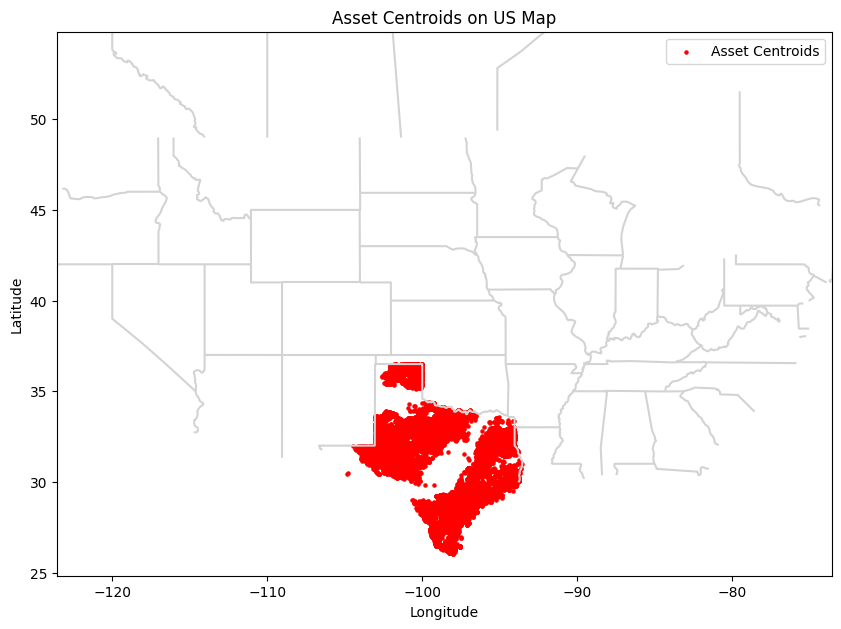

In [ ]:
# prompt: Visualize the data by plotting the centroid_longitude	centroid_latitude on a US map

import matplotlib.pyplot as plt

# Create a GeoDataFrame
geometry = [Point(xy) for xy in zip(grouped_SFOO_df['longitude'], grouped_SFOO_df['latitude'])]
gdf = gpd.GeoDataFrame(grouped_SFOO_df, geometry=geometry, crs="EPSG:4326")

# Load US states shapefile
States = gpd.read_file('/content/drive/MyDrive/Russia and Ukrainian Conflict, Fossil Fuel Map/Russia and Ukraine, QGIS files/Natural_Earth_quick_start/50m_cultural/ne_50m_admin_1_states_provinces_lines.shp')

 # Define the center point for Texas (approximately)
center_longitude = -98.5795
center_latitude = 39.8283

# Set the extent for zooming (adjust as needed)
x_min = center_longitude - 25  # 10 degrees of longitude to the left
x_max = center_longitude + 25  # 10 degrees of longitude to the right
y_min = center_latitude - 15   # 5 degrees of latitude below
y_max = center_latitude + 15   # 5 degrees of latitude above

# Plot the map
fig, ax = plt.subplots(figsize=(10, 10))
States.plot(ax=ax, color='lightgray', edgecolor='black')

# Plot the centroids on the map
gdf.plot(ax=ax, marker='o', color='red', markersize=5, label='Asset Centroids')

# Customize the plot
plt.title('Asset Centroids on US Map')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Set the map extent to zoom in on the US
ax.set_xlim([x_min, x_max])
ax.set_ylim([y_min, y_max])

plt.legend()
plt.show()

In [ ]:
# prompt: Create total hydrocarbons column, adding oil_vol	and condensate_vol, and converting gas_dry_vol to million boe

# Calculate total hydrocarbons
grouped_SFOO_df['total_hydrocarbons'] = grouped_SFOO_df['oil_and_condensate_vol'] + grouped_SFOO_df['ngl_vol'] + (grouped_SFOO_df['gas_dry_vol'] * gas_conversion_factor)
#grouped_FOO_df['total_hydrocarbons'] = grouped_FOO_df['oil_vol'] + grouped_FOO_df['condensate_vol'] + (grouped_FOO_df['gas_dry_vol'] * gas_conversion_factor)
# grouped_PA_df ['total_hydrocarbons'] = grouped_PA_df['oil_vol'] + grouped_PA_df['condensate_vol'] + grouped_PA_df['ngl_vol'] + (grouped_PA_df['gas_raw_vol'] * gas_conversion_factor) # using Raw gas for PA as raw gas appears not to be modelled

grouped_SFOO_df

,field_name,formation_name,operator_name,oil_and_condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol,well_no,recovery_mechanism,resource_type,field_terrain,country,state,oil_gravity,gas_gravity,longitude,latitude,asset_name,total_hydrocarbons
0,-TT- (CONGLOMERATE),CONGLOMERATE,"MARTIS VALLEY ENERGY, LLC",0.003163,0.000000,0.000000,0.000000,,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,40.000000,NaN,-99.159958,33.918530,"-Tt- (Conglomerate) - Martis Valley Energy, Llc",0.003163
1,"-Y-, SOUTH (TUBB 4130)",TUBB 4130,PETROPLEX ENERGY INC.,0.000000,0.079542,0.052648,0.000344,200230.0,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,NaN,0.880000,-102.637072,31.327126,"-Y-, South (Tubb 4130) - Petroplex Energy Inc.",0.000654
2,"-Y-, SOUTH (TUBB)",TUBB,PETEX,0.000449,0.071302,0.071302,0.000000,,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,35.000000,NaN,-102.629666,31.345670,"-Y-, South (Tubb) - Petex",0.000868
3,A & D (MARBLE FALLS CONGL. 4900),MARBLE FALLS CONGL. 4900,GUIDANCE OIL DEVELOPERS,0.000299,0.000000,0.000000,0.000000,,Recovery Mechanism Not Stated in delivered data,Conventional,Offshore,united_states,texas,42.000000,NaN,-98.750741,33.425862,A & D (Marble Falls Congl. 4900) - Guidance Oi...,0.000299
4,A & D (MARBLE FALLS CONGL. 4900),MARBLE FALLS CONGL. 4900,WALKER OPERATING (I),0.000520,0.000000,0.000000,0.000000,,Recovery Mechanism Not Stated in delivered data,Conventional,Offshore,united_states,texas,42.000000,NaN,-98.695177,33.431511,A & D (Marble Falls Congl. 4900) - Walker Oper...,0.000520
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22073,ZWEBB (10350),10350,"KILLAM OIL CO., LTD.",0.000370,2.764630,2.753105,0.000000,182944.0; 186023.0,Recovery Mechanism Not Stated in delivered data,Unconventional,Onshore,united_states,texas,50.000000,0.635000,-99.024134,27.274147,"Zwebb (10350) - Killam Oil Co., Ltd.",0.016567
22074,ZWEBB (10350),10350,SMITH PRODUCTION INC.,0.004096,21.630729,18.830023,0.000000,173763.0; 174219.0; 174612.0; 175017.0; 175486...,Recovery Mechanism Not Stated in delivered da...,Unconventional,Onshore,united_states,texas,50.182353,0.644922,-99.057342,27.286541,Zwebb (10350) - Smith Production Inc.,0.114873
22075,ZWEBB (9200),9200,"HUGOTON OPERATING COMPANY, INC.",0.000000,0.039813,0.025882,0.000000,279125.0,Hydraulic fracturing,Unconventional,Onshore,united_states,texas,43.900000,0.600000,-98.998796,27.284932,"Zwebb (9200) - Hugoton Operating Company, Inc.",0.000152
22076,ZYBACH (MORROW),MORROW,ATLAS OPERATING LLC,0.000000,0.131305,0.131305,0.000000,104342.0,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,57.000000,0.585000,-100.234988,35.551429,Zybach (Morrow) - Atlas Operating Llc,0.000772


In [ ]:
# Filter out Pennsylvania data from filtered_SFOO_df
filtered_SFOO_df = grouped_SFOO_df[grouped_SFOO_df['state'] != 'pennsylvania']

# Concatenate the filtered DataFrame with grouped_PA_df
updated_SFOO_df = pd.concat([filtered_SFOO_df, grouped_PA_df], ignore_index=True)

In [ ]:
# for ease, redefine the PA replaced data, as the grouped data
grouped_SFOO_df = updated_SFOO_df

NameError: name 'updated_SFOO_df' is not defined

In [ ]:
# check state totals in grouped_SFOO_df
grouped_state_totals_unfiltered = grouped_SFOO_df.groupby('state')[['oil_and_condensate_vol', 'gas_raw_vol', 'gas_dry_vol', 'ngl_vol', 'total_hydrocarbons']].sum().reset_index()

grouped_state_totals_unfiltered

,state,oil_and_condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol,total_hydrocarbons
0,texas,2062.99726,374899.221792,288552.264139,824.270919,4584.821149


In [ ]:
# sort on total_hydrocarbons
grouped_SFOO_sorted_df = grouped_SFOO_df.sort_values(by='total_hydrocarbons', ascending=False)
#grouped_FOO_sorted_df = grouped_FOO_df.sort_values(by='total_hydrocarbons', ascending=False)
grouped_SFOO_sorted_df

,field_name,formation_name,operator_name,oil_and_condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol,well_no,recovery_mechanism,resource_type,field_terrain,country,state,oil_gravity,gas_gravity,longitude,latitude,asset_name,total_hydrocarbons
18394,SPRABERRY (TREND AREA),TREND AREA,DIAMONDBACK E&P LLC,204.199098,18280.341487,14912.365402,33.330213,215159.0; 295113.0,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,34.762646,0.756500,-101.930880,32.086129,Spraberry (Trend Area) - Diamondback E&P Llc,325.258757
18464,SPRABERRY (TREND AREA),TREND AREA,"PIONEER NATURAL RES. USA, INC.",182.949715,16862.110320,11069.528031,70.195236,282322.0; 291857.0,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,35.269831,0.780500,-101.890727,31.920797,Spraberry (Trend Area) - Pioneer Natural Res. ...,318.266985
15421,PHANTOM (WOLFCAMP),WOLFCAMP,ANADARKO E&P ONSHORE LLC,77.388628,9467.429007,5541.165405,34.476196,276220.0; 276320.0; 276322.0; 276516.0; 276545...,Hydraulic fracturing; Recovery Mechanism Not ...,Unconventional,Onshore,united_states,texas,48.809014,0.783118,-103.674167,31.786738,Phantom (Wolfcamp) - Anadarko E&P Onshore Llc,144.463500
18517,SPRABERRY (TREND AREA),TREND AREA,XTO ENERGY INC.,41.571063,5188.169592,3430.556907,21.754190,,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,34.375000,NaN,-101.904534,31.898220,Spraberry (Trend Area) - Xto Energy Inc.,83.507219
18447,SPRABERRY (TREND AREA),TREND AREA,OVINTIV USA INC.,45.761344,4314.033833,2812.307560,17.833730,290930.0,Hydraulic fracturing; Recovery Mechanism Not ...,Unconventional; Conventional,Onshore,united_states,texas,34.544478,0.750000,-101.904696,32.149968,Spraberry (Trend Area) - Ovintiv Usa Inc.,80.139880
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19036,SWANSON (2950),2950,"VIPER S.W.D., LLC",0.000000,0.005663,0.000000,0.000000,133167.0,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,NaN,0.565000,-96.427897,29.225489,"Swanson (2950) - Viper S.W.D., Llc",0.000000
10739,"KOHLER, NE. (QUEEN CITY 4TH)",QUEEN CITY 4TH,"KD ENERGY, LLC",0.000000,0.026476,0.000000,0.000000,197818.0,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,NaN,0.586000,-98.753185,27.649295,"Kohler, Ne. (Queen City 4Th) - Kd Energy, Llc",0.000000
14330,"OZONA, NW. (SPRABERRY)",SPRABERRY,"MAYJAC I, LLC",0.000000,0.030526,0.000000,0.000000,283987.0,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,NaN,0.738000,-101.244738,30.702234,"Ozona, Nw. (Spraberry) - Mayjac I, Llc",0.000000
14319,"OZONA, NE. (CANYON SAND)",CANYON SAND,"MAYJAC I, LLC",0.000000,0.858029,0.000000,0.000000,134430.0; 137098.0; 139227.0; 143599.0; 145793...,Recovery Mechanism Not Stated in delivered data,Unconventional; Conventional,Onshore,united_states,texas,71.616667,0.747500,-101.244140,30.689815,"Ozona, Ne. (Canyon Sand) - Mayjac I, Llc",0.000000


In [ ]:
def filter_top_producers(df, group_col, value_col, percentile=0.95):
    """
    Filters a DataFrame to include rows representing the top percentile of a value
    within each group.

    Args:
        df: The input DataFrame.
        group_col: The column to group by (e.g., 'state').
        value_col: The column containing the value to rank by (e.g., 'total_hydrocarbons').
        percentile: The desired percentile (default is 0.95 for top 95%).

    Returns:
        A filtered DataFrame.
    """

    df['cumulative_sum'] = df.groupby(group_col)[value_col].cumsum()
    state_totals = df.groupby(group_col)[value_col].transform('sum')  # Using transform for efficiency
    df['threshold'] = state_totals * percentile
    filtered_df = df[df['cumulative_sum'] <= df['threshold']]

    return filtered_df.drop(columns=['cumulative_sum', 'threshold'])  # Remove temporary columns

# Apply the function
filteredSFOO_df = filter_top_producers(
    grouped_SFOO_sorted_df,
    group_col='state',
    value_col='total_hydrocarbons'
)
filteredSFOO_df

,field_name,formation_name,operator_name,oil_and_condensate_vol,gas_raw_vol,gas_dry_vol,ngl_vol,well_no,recovery_mechanism,resource_type,field_terrain,country,state,oil_gravity,gas_gravity,longitude,latitude,asset_name,total_hydrocarbons
18394,SPRABERRY (TREND AREA),TREND AREA,DIAMONDBACK E&P LLC,204.199098,18280.341487,14912.365402,33.330213,215159.0; 295113.0,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,34.762646,0.756500,-101.930880,32.086129,Spraberry (Trend Area) - Diamondback E&P Llc,325.258757
18464,SPRABERRY (TREND AREA),TREND AREA,"PIONEER NATURAL RES. USA, INC.",182.949715,16862.110320,11069.528031,70.195236,282322.0; 291857.0,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,35.269831,0.780500,-101.890727,31.920797,Spraberry (Trend Area) - Pioneer Natural Res. ...,318.266985
15421,PHANTOM (WOLFCAMP),WOLFCAMP,ANADARKO E&P ONSHORE LLC,77.388628,9467.429007,5541.165405,34.476196,276220.0; 276320.0; 276322.0; 276516.0; 276545...,Hydraulic fracturing; Recovery Mechanism Not ...,Unconventional,Onshore,united_states,texas,48.809014,0.783118,-103.674167,31.786738,Phantom (Wolfcamp) - Anadarko E&P Onshore Llc,144.463500
18517,SPRABERRY (TREND AREA),TREND AREA,XTO ENERGY INC.,41.571063,5188.169592,3430.556907,21.754190,,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,34.375000,NaN,-101.904534,31.898220,Spraberry (Trend Area) - Xto Energy Inc.,83.507219
18447,SPRABERRY (TREND AREA),TREND AREA,OVINTIV USA INC.,45.761344,4314.033833,2812.307560,17.833730,290930.0,Hydraulic fracturing; Recovery Mechanism Not ...,Unconventional; Conventional,Onshore,united_states,texas,34.544478,0.750000,-101.904696,32.149968,Spraberry (Trend Area) - Ovintiv Usa Inc.,80.139880
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18593,ST. CLAIR (GRANITE WASH),GRANITE WASH,"TEXAKOMA E & P, LLC",0.090651,38.717058,21.935557,0.139875,230350.0; 234168.0; 236331.0; 239329.0; 242482...,Recovery Mechanism Not Stated in delivered da...,Unconventional; Conventional,Onshore,united_states,texas,44.381481,0.732733,-100.681148,35.891015,"St. Clair (Granite Wash) - Texakoma E & P, Llc",0.359573
18452,SPRABERRY (TREND AREA),TREND AREA,"P1 ENERGY, LLC",0.086232,32.869544,22.301828,0.141894,129157.0; 131261.0; 136443.0; 136445.0; 139339...,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,43.897260,0.808891,-101.156785,31.568885,"Spraberry (Trend Area) - P1 Energy, Llc",0.359328
20835,WASSON,No Formation Stated in delivered data,XTO ENERGY INC.,0.192081,21.121281,15.161675,0.077457,,Hydraulic fracturing,Unconventional,Onshore,united_states,texas,NaN,NaN,-102.741578,33.044219,Wasson - Xto Energy Inc.,0.358734
235,AGUA DULCE (CONSOLIDATED FRIO),CONSOLIDATED FRIO,"URBAN OIL & GAS GROUP, LLC",0.000000,44.805945,28.855235,0.187946,101862.0; 122922.0; 122924.0; 128402.0; 129131...,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,55.750000,0.654185,-97.862869,27.735873,Agua Dulce (Consolidated Frio) - Urban Oil & G...,0.357702


In [ ]:
#compare filtered (filteredSFOO_df) and unfiltered (grouped_SFOO_sorted_df) state totals

# calculate filteredSFOO_df state totals
filtered_state_totals = filteredSFOO_df.groupby('state')[['total_hydrocarbons']].sum().reset_index()


# calculate unfiltered state totals
unfiltered_state_totals = grouped_SFOO_sorted_df.groupby('state')[['total_hydrocarbons']].sum().reset_index()

filtered_state_totals

,state,total_hydrocarbons
0,texas,4355.335211


In [ ]:
unfiltered_state_totals

,state,total_hydrocarbons
0,texas,4584.821149


In [ ]:
# Data Cleaning
# Rename columns for clarity
filteredSFOO_clean = filteredSFOO_df.rename(columns={
    'oil_and_condensate_vol': 'Oil and Condensate production (million bbl/y)',
    'gas_raw_vol': 'Raw gas production (million m³/y)',
    'gas_dry_vol': 'Dry gas production (million m³/y)',
    'well_no': 'Well ID(s)',
    'ngl_vol': 'NGL production (million bbl/y)',
    'recovery_mechanism': 'Recovery mechanism',
    'longitude': 'Longitude',
    'latitude': 'Latitude',
    'total_hydrocarbons': 'Total hydrocarbon production (million bbl/y)',
    'cumulative_sum': 'Cumulative sum',
    'threshold': 'State Inclusion Threshold',
    'owner_name': 'Owner',
    'operator_name': 'Operator',
    'resource_type': 'Resource Type',
    'field_terrain': 'Onshore/Offshore',
    'field_name': 'Field Name',
    'formation_name': 'Formation Name',
    'country': 'Country/Area',
    'state': 'Subnational unit (province, state)',
    'county_name': 'county'
})

In [ ]:
filteredSFOO_clean

,Field Name,Formation Name,Operator,Oil and Condensate production (million bbl/y),Raw gas production (million m³/y),Dry gas production (million m³/y),NGL production (million bbl/y),Well ID(s),Recovery mechanism,Resource Type,Onshore/Offshore,Country/Area,"Subnational unit (province, state)",oil_gravity,gas_gravity,Longitude,Latitude,asset_name,Total hydrocarbon production (million bbl/y)
18394,SPRABERRY (TREND AREA),TREND AREA,DIAMONDBACK E&P LLC,204.199098,18280.341487,14912.365402,33.330213,215159.0; 295113.0,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,34.762646,0.756500,-101.930880,32.086129,Spraberry (Trend Area) - Diamondback E&P Llc,325.258757
18464,SPRABERRY (TREND AREA),TREND AREA,"PIONEER NATURAL RES. USA, INC.",182.949715,16862.110320,11069.528031,70.195236,282322.0; 291857.0,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,35.269831,0.780500,-101.890727,31.920797,Spraberry (Trend Area) - Pioneer Natural Res. ...,318.266985
15421,PHANTOM (WOLFCAMP),WOLFCAMP,ANADARKO E&P ONSHORE LLC,77.388628,9467.429007,5541.165405,34.476196,276220.0; 276320.0; 276322.0; 276516.0; 276545...,Hydraulic fracturing; Recovery Mechanism Not ...,Unconventional,Onshore,united_states,texas,48.809014,0.783118,-103.674167,31.786738,Phantom (Wolfcamp) - Anadarko E&P Onshore Llc,144.463500
18517,SPRABERRY (TREND AREA),TREND AREA,XTO ENERGY INC.,41.571063,5188.169592,3430.556907,21.754190,,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,34.375000,NaN,-101.904534,31.898220,Spraberry (Trend Area) - Xto Energy Inc.,83.507219
18447,SPRABERRY (TREND AREA),TREND AREA,OVINTIV USA INC.,45.761344,4314.033833,2812.307560,17.833730,290930.0,Hydraulic fracturing; Recovery Mechanism Not ...,Unconventional; Conventional,Onshore,united_states,texas,34.544478,0.750000,-101.904696,32.149968,Spraberry (Trend Area) - Ovintiv Usa Inc.,80.139880
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18593,ST. CLAIR (GRANITE WASH),GRANITE WASH,"TEXAKOMA E & P, LLC",0.090651,38.717058,21.935557,0.139875,230350.0; 234168.0; 236331.0; 239329.0; 242482...,Recovery Mechanism Not Stated in delivered da...,Unconventional; Conventional,Onshore,united_states,texas,44.381481,0.732733,-100.681148,35.891015,"St. Clair (Granite Wash) - Texakoma E & P, Llc",0.359573
18452,SPRABERRY (TREND AREA),TREND AREA,"P1 ENERGY, LLC",0.086232,32.869544,22.301828,0.141894,129157.0; 131261.0; 136443.0; 136445.0; 139339...,Recovery Mechanism Not Stated in delivered da...,Conventional; Unconventional,Onshore,united_states,texas,43.897260,0.808891,-101.156785,31.568885,"Spraberry (Trend Area) - P1 Energy, Llc",0.359328
20835,WASSON,No Formation Stated in delivered data,XTO ENERGY INC.,0.192081,21.121281,15.161675,0.077457,,Hydraulic fracturing,Unconventional,Onshore,united_states,texas,NaN,NaN,-102.741578,33.044219,Wasson - Xto Energy Inc.,0.358734
235,AGUA DULCE (CONSOLIDATED FRIO),CONSOLIDATED FRIO,"URBAN OIL & GAS GROUP, LLC",0.000000,44.805945,28.855235,0.187946,101862.0; 122922.0; 122924.0; 128402.0; 129131...,Recovery Mechanism Not Stated in delivered data,Conventional,Onshore,united_states,texas,55.750000,0.654185,-97.862869,27.735873,Agua Dulce (Consolidated Frio) - Urban Oil & G...,0.357702


In [ ]:
# reorder columns
filtered_df_clean_reorder = filteredSFOO_clean[['Country/Area', 'Subnational unit (province, state)', 'Field Name', 'asset_name', 'Formation Name', 'Well ID(s)', 'Longitude', 'Latitude','Operator', 'Resource Type', 'Recovery mechanism', 'Onshore/Offshore', 'Oil and Condensate production (million bbl/y)', 'Raw gas production (million m³/y)', 'Dry gas production (million m³/y)', 'NGL production (million bbl/y)','Total hydrocarbon production (million bbl/y)']]


In [ ]:
# prompt: title case data in the  field name, operator, owner, country, state columns

# Assuming 'filtered_df' is your DataFrame

# Columns to title case
columns_to_title_case = ['Field Name', 'Operator', 'Owner', 'Country/Area', 'Subnational unit (province, state)','Formation Name']

# Title case the specified columns
for col in columns_to_title_case:
    if col in filtered_df_clean_reorder.columns:
        filtered_df_clean_reorder.loc[:, col] = filtered_df_clean_reorder[col].str.title()

# Example usage for further processing or display
filtered_df_clean_reorder


,Country/Area,"Subnational unit (province, state)",Field Name,asset_name,Formation Name,Well ID(s),Longitude,Latitude,Operator,Resource Type,Recovery mechanism,Onshore/Offshore,Oil and Condensate production (million bbl/y),Raw gas production (million m³/y),Dry gas production (million m³/y),NGL production (million bbl/y),Total hydrocarbon production (million bbl/y)
18394,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Diamondback E&P Llc,Trend Area,215159.0; 295113.0,-101.930880,32.086129,Diamondback E&P Llc,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,204.199098,18280.341487,14912.365402,33.330213,325.258757
18464,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Pioneer Natural Res. ...,Trend Area,282322.0; 291857.0,-101.890727,31.920797,"Pioneer Natural Res. Usa, Inc.",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,182.949715,16862.110320,11069.528031,70.195236,318.266985
15421,United_States,Texas,Phantom (Wolfcamp),Phantom (Wolfcamp) - Anadarko E&P Onshore Llc,Wolfcamp,276220.0; 276320.0; 276322.0; 276516.0; 276545...,-103.674167,31.786738,Anadarko E&P Onshore Llc,Unconventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,77.388628,9467.429007,5541.165405,34.476196,144.463500
18517,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Xto Energy Inc.,Trend Area,,-101.904534,31.898220,Xto Energy Inc.,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,41.571063,5188.169592,3430.556907,21.754190,83.507219
18447,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Ovintiv Usa Inc.,Trend Area,290930.0,-101.904696,32.149968,Ovintiv Usa Inc.,Unconventional; Conventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,45.761344,4314.033833,2812.307560,17.833730,80.139880
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18593,United_States,Texas,St. Clair (Granite Wash),"St. Clair (Granite Wash) - Texakoma E & P, Llc",Granite Wash,230350.0; 234168.0; 236331.0; 239329.0; 242482...,-100.681148,35.891015,"Texakoma E & P, Llc",Unconventional; Conventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.090651,38.717058,21.935557,0.139875,0.359573
18452,United_States,Texas,Spraberry (Trend Area),"Spraberry (Trend Area) - P1 Energy, Llc",Trend Area,129157.0; 131261.0; 136443.0; 136445.0; 139339...,-101.156785,31.568885,"P1 Energy, Llc",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.086232,32.869544,22.301828,0.141894,0.359328
20835,United_States,Texas,Wasson,Wasson - Xto Energy Inc.,No Formation Stated In Delivered Data,,-102.741578,33.044219,Xto Energy Inc.,Unconventional,Hydraulic fracturing,Onshore,0.192081,21.121281,15.161675,0.077457,0.358734
235,United_States,Texas,Agua Dulce (Consolidated Frio),Agua Dulce (Consolidated Frio) - Urban Oil & G...,Consolidated Frio,101862.0; 122922.0; 122924.0; 128402.0; 129131...,-97.862869,27.735873,"Urban Oil & Gas Group, Llc",Conventional,Recovery Mechanism Not Stated in delivered data,Onshore,0.000000,44.805945,28.855235,0.187946,0.357702


In [ ]:
# Add in Government Formation ID and Operator ID for Texas
# Define texas subset
texas_subset = filtered_df_clean_reorder[filtered_df_clean_reorder['Subnational unit (province, state)'] == 'Texas']

# load in df with texas field/formation names/numbers and operator names/numbers
texas_IDOP_excel = goget_path + '/Data sets & reports (O&G)/O&G country materials/United States (GOGET O&G)/Texas (GOGET)/Texas 2023 Field and Operator Names.xlsx'

# load in texas excel doc, define tabs
texas_Field_ids = pd.read_excel(texas_IDOP_excel, sheet_name='Field and Formation Name')
texas_op_ids = pd.read_excel(texas_IDOP_excel, sheet_name='Operator Name')


In [ ]:
# prompt: add Field_No to from texas_Field_ids to texas_subset matching FIELD_NAME to Field Name

# title case field name on texas_Field_ids
texas_Field_ids['FIELD_NAME'] = texas_Field_ids['FIELD_NAME'].str.title()

# convert field_no to string
texas_Field_ids['Field_No'] = texas_Field_ids['Field_No'].astype(str)


# Merge texas_subset with texas_Field_ids based on 'Field Name'
texas_subset = pd.merge(texas_subset, texas_Field_ids[['FIELD_NAME', 'Field_No']], left_on='Field Name', right_on='FIELD_NAME', how='left')

# Drop the duplicate 'FIELD_NAME' column
texas_subset = texas_subset.drop(columns=['FIELD_NAME'])

texas_subset

,Country/Area,"Subnational unit (province, state)",Field Name,asset_name,Formation Name,Well ID(s),Longitude,Latitude,Operator,Resource Type,Recovery mechanism,Onshore/Offshore,Oil and Condensate production (million bbl/y),Raw gas production (million m³/y),Dry gas production (million m³/y),NGL production (million bbl/y),Total hydrocarbon production (million bbl/y),Field_No
0,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Diamondback E&P Llc,Trend Area,215159.0; 295113.0,-101.930880,32.086129,Diamondback E&P Llc,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,204.199098,18280.341487,14912.365402,33.330213,325.258757,85279200
1,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Pioneer Natural Res. ...,Trend Area,282322.0; 291857.0,-101.890727,31.920797,"Pioneer Natural Res. Usa, Inc.",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,182.949715,16862.110320,11069.528031,70.195236,318.266985,85279200
2,United_States,Texas,Phantom (Wolfcamp),Phantom (Wolfcamp) - Anadarko E&P Onshore Llc,Wolfcamp,276220.0; 276320.0; 276322.0; 276516.0; 276545...,-103.674167,31.786738,Anadarko E&P Onshore Llc,Unconventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,77.388628,9467.429007,5541.165405,34.476196,144.463500,71052900
3,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Xto Energy Inc.,Trend Area,,-101.904534,31.898220,Xto Energy Inc.,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,41.571063,5188.169592,3430.556907,21.754190,83.507219,85279200
4,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Ovintiv Usa Inc.,Trend Area,290930.0,-101.904696,32.149968,Ovintiv Usa Inc.,Unconventional; Conventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,45.761344,4314.033833,2812.307560,17.833730,80.139880,85279200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
605,United_States,Texas,St. Clair (Granite Wash),"St. Clair (Granite Wash) - Texakoma E & P, Llc",Granite Wash,230350.0; 234168.0; 236331.0; 239329.0; 242482...,-100.681148,35.891015,"Texakoma E & P, Llc",Unconventional; Conventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.090651,38.717058,21.935557,0.139875,0.359573,79636500
606,United_States,Texas,Spraberry (Trend Area),"Spraberry (Trend Area) - P1 Energy, Llc",Trend Area,129157.0; 131261.0; 136443.0; 136445.0; 139339...,-101.156785,31.568885,"P1 Energy, Llc",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.086232,32.869544,22.301828,0.141894,0.359328,85279200
607,United_States,Texas,Wasson,Wasson - Xto Energy Inc.,No Formation Stated In Delivered Data,,-102.741578,33.044219,Xto Energy Inc.,Unconventional,Hydraulic fracturing,Onshore,0.192081,21.121281,15.161675,0.077457,0.358734,95397001
608,United_States,Texas,Agua Dulce (Consolidated Frio),Agua Dulce (Consolidated Frio) - Urban Oil & G...,Consolidated Frio,101862.0; 122922.0; 122924.0; 128402.0; 129131...,-97.862869,27.735873,"Urban Oil & Gas Group, Llc",Conventional,Recovery Mechanism Not Stated in delivered data,Onshore,0.000000,44.805945,28.855235,0.187946,0.357702,832092


In [ ]:
# add Operator_No to from texas_op_ids to texas_subset matching OPERATOR_NAME to Operator

# title case field name on texas_Field_ids
texas_op_ids['OPERATOR_NAME'] = texas_op_ids['OPERATOR_NAME'].str.title()

# convert Operator_no to string
texas_op_ids['Operator_no'] = texas_op_ids['Operator_no'].astype(str)

# Merge texas_subset with texas_op_ids based on 'Operator'
texas_subset = pd.merge(texas_subset, texas_op_ids[['OPERATOR_NAME', 'Operator_no']], left_on='Operator', right_on='OPERATOR_NAME', how='left')

# Drop the duplicate 'OPERATOR_NAME' column
texas_subset = texas_subset.drop(columns=['OPERATOR_NAME'])

texas_subset

,Country/Area,"Subnational unit (province, state)",Field Name,asset_name,Formation Name,Well ID(s),Longitude,Latitude,Operator,Resource Type,Recovery mechanism,Onshore/Offshore,Oil and Condensate production (million bbl/y),Raw gas production (million m³/y),Dry gas production (million m³/y),NGL production (million bbl/y),Total hydrocarbon production (million bbl/y),Field_No,Operator_no
0,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Diamondback E&P Llc,Trend Area,215159.0; 295113.0,-101.930880,32.086129,Diamondback E&P Llc,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,204.199098,18280.341487,14912.365402,33.330213,325.258757,85279200,217012
1,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Pioneer Natural Res. ...,Trend Area,282322.0; 291857.0,-101.890727,31.920797,"Pioneer Natural Res. Usa, Inc.",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,182.949715,16862.110320,11069.528031,70.195236,318.266985,85279200,665748
2,United_States,Texas,Phantom (Wolfcamp),Phantom (Wolfcamp) - Anadarko E&P Onshore Llc,Wolfcamp,276220.0; 276320.0; 276322.0; 276516.0; 276545...,-103.674167,31.786738,Anadarko E&P Onshore Llc,Unconventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,77.388628,9467.429007,5541.165405,34.476196,144.463500,71052900,20528
3,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Xto Energy Inc.,Trend Area,,-101.904534,31.898220,Xto Energy Inc.,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,41.571063,5188.169592,3430.556907,21.754190,83.507219,85279200,945936
4,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Ovintiv Usa Inc.,Trend Area,290930.0,-101.904696,32.149968,Ovintiv Usa Inc.,Unconventional; Conventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,45.761344,4314.033833,2812.307560,17.833730,80.139880,85279200,628658
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
605,United_States,Texas,St. Clair (Granite Wash),"St. Clair (Granite Wash) - Texakoma E & P, Llc",Granite Wash,230350.0; 234168.0; 236331.0; 239329.0; 242482...,-100.681148,35.891015,"Texakoma E & P, Llc",Unconventional; Conventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.090651,38.717058,21.935557,0.139875,0.359573,79636500,844133
606,United_States,Texas,Spraberry (Trend Area),"Spraberry (Trend Area) - P1 Energy, Llc",Trend Area,129157.0; 131261.0; 136443.0; 136445.0; 139339...,-101.156785,31.568885,"P1 Energy, Llc",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.086232,32.869544,22.301828,0.141894,0.359328,85279200,NaN
607,United_States,Texas,Wasson,Wasson - Xto Energy Inc.,No Formation Stated In Delivered Data,,-102.741578,33.044219,Xto Energy Inc.,Unconventional,Hydraulic fracturing,Onshore,0.192081,21.121281,15.161675,0.077457,0.358734,95397001,945936
608,United_States,Texas,Agua Dulce (Consolidated Frio),Agua Dulce (Consolidated Frio) - Urban Oil & G...,Consolidated Frio,101862.0; 122922.0; 122924.0; 128402.0; 129131...,-97.862869,27.735873,"Urban Oil & Gas Group, Llc",Conventional,Recovery Mechanism Not Stated in delivered data,Onshore,0.000000,44.805945,28.855235,0.187946,0.357702,832092,879035


In [ ]:
# Create "Government unit ID" as Field_No + "_" + Operator_no
texas_subset['Government unit ID'] = texas_subset['Field_No'] + '_' + texas_subset['Operator_no']

texas_subset

,Country/Area,"Subnational unit (province, state)",Field Name,asset_name,Formation Name,Well ID(s),Longitude,Latitude,Operator,Resource Type,Recovery mechanism,Onshore/Offshore,Oil and Condensate production (million bbl/y),Raw gas production (million m³/y),Dry gas production (million m³/y),NGL production (million bbl/y),Total hydrocarbon production (million bbl/y),Field_No,Operator_no,Government unit ID
0,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Diamondback E&P Llc,Trend Area,215159.0; 295113.0,-101.930880,32.086129,Diamondback E&P Llc,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,204.199098,18280.341487,14912.365402,33.330213,325.258757,85279200,217012,85279200_217012
1,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Pioneer Natural Res. ...,Trend Area,282322.0; 291857.0,-101.890727,31.920797,"Pioneer Natural Res. Usa, Inc.",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,182.949715,16862.110320,11069.528031,70.195236,318.266985,85279200,665748,85279200_665748
2,United_States,Texas,Phantom (Wolfcamp),Phantom (Wolfcamp) - Anadarko E&P Onshore Llc,Wolfcamp,276220.0; 276320.0; 276322.0; 276516.0; 276545...,-103.674167,31.786738,Anadarko E&P Onshore Llc,Unconventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,77.388628,9467.429007,5541.165405,34.476196,144.463500,71052900,20528,71052900_20528
3,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Xto Energy Inc.,Trend Area,,-101.904534,31.898220,Xto Energy Inc.,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,41.571063,5188.169592,3430.556907,21.754190,83.507219,85279200,945936,85279200_945936
4,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Ovintiv Usa Inc.,Trend Area,290930.0,-101.904696,32.149968,Ovintiv Usa Inc.,Unconventional; Conventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,45.761344,4314.033833,2812.307560,17.833730,80.139880,85279200,628658,85279200_628658
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
605,United_States,Texas,St. Clair (Granite Wash),"St. Clair (Granite Wash) - Texakoma E & P, Llc",Granite Wash,230350.0; 234168.0; 236331.0; 239329.0; 242482...,-100.681148,35.891015,"Texakoma E & P, Llc",Unconventional; Conventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.090651,38.717058,21.935557,0.139875,0.359573,79636500,844133,79636500_844133
606,United_States,Texas,Spraberry (Trend Area),"Spraberry (Trend Area) - P1 Energy, Llc",Trend Area,129157.0; 131261.0; 136443.0; 136445.0; 139339...,-101.156785,31.568885,"P1 Energy, Llc",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.086232,32.869544,22.301828,0.141894,0.359328,85279200,NaN,NaN
607,United_States,Texas,Wasson,Wasson - Xto Energy Inc.,No Formation Stated In Delivered Data,,-102.741578,33.044219,Xto Energy Inc.,Unconventional,Hydraulic fracturing,Onshore,0.192081,21.121281,15.161675,0.077457,0.358734,95397001,945936,95397001_945936
608,United_States,Texas,Agua Dulce (Consolidated Frio),Agua Dulce (Consolidated Frio) - Urban Oil & G...,Consolidated Frio,101862.0; 122922.0; 122924.0; 128402.0; 129131...,-97.862869,27.735873,"Urban Oil & Gas Group, Llc",Conventional,Recovery Mechanism Not Stated in delivered data,Onshore,0.000000,44.805945,28.855235,0.187946,0.357702,832092,879035,832092_879035


In [ ]:
# prompt: Merge the "Government unit ID" from texas_subset onto filtered_df_clean_reorder, adding a new column

filtered_df_clean_reorder['Field Name'] = filtered_df_clean_reorder['Field Name'].astype(str)
texas_subset['Field Name'] = texas_subset['Field Name'].astype(str)

filtered_df_clean_reorder['Operator'] = filtered_df_clean_reorder['Operator'].astype(str)
texas_subset['Operator'] = texas_subset['Operator'].astype(str)

# Merge the "Government unit ID" from texas_subset onto filtered_df_clean_reorder
filtered_df_clean_reorder_govid = pd.merge(filtered_df_clean_reorder, texas_subset[['Government unit ID', 'Field Name', 'Operator']], on=['Field Name', 'Operator'], how='left')

filtered_df_clean_reorder_govid

/tmp/ipython-input-1346030988.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df_clean_reorder['Field Name'] = filtered_df_clean_reorder['Field Name'].astype(str)
/tmp/ipython-input-1346030988.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df_clean_reorder['Operator'] = filtered_df_clean_reorder['Operator'].astype(str)


,Country/Area,"Subnational unit (province, state)",Field Name,asset_name,Formation Name,Well ID(s),Longitude,Latitude,Operator,Resource Type,Recovery mechanism,Onshore/Offshore,Oil and Condensate production (million bbl/y),Raw gas production (million m³/y),Dry gas production (million m³/y),NGL production (million bbl/y),Total hydrocarbon production (million bbl/y),Government unit ID
0,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Diamondback E&P Llc,Trend Area,215159.0; 295113.0,-101.930880,32.086129,Diamondback E&P Llc,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,204.199098,18280.341487,14912.365402,33.330213,325.258757,85279200_217012
1,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Pioneer Natural Res. ...,Trend Area,282322.0; 291857.0,-101.890727,31.920797,"Pioneer Natural Res. Usa, Inc.",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,182.949715,16862.110320,11069.528031,70.195236,318.266985,85279200_665748
2,United_States,Texas,Phantom (Wolfcamp),Phantom (Wolfcamp) - Anadarko E&P Onshore Llc,Wolfcamp,276220.0; 276320.0; 276322.0; 276516.0; 276545...,-103.674167,31.786738,Anadarko E&P Onshore Llc,Unconventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,77.388628,9467.429007,5541.165405,34.476196,144.463500,71052900_20528
3,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Xto Energy Inc.,Trend Area,,-101.904534,31.898220,Xto Energy Inc.,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,41.571063,5188.169592,3430.556907,21.754190,83.507219,85279200_945936
4,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Ovintiv Usa Inc.,Trend Area,290930.0,-101.904696,32.149968,Ovintiv Usa Inc.,Unconventional; Conventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,45.761344,4314.033833,2812.307560,17.833730,80.139880,85279200_628658
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
605,United_States,Texas,St. Clair (Granite Wash),"St. Clair (Granite Wash) - Texakoma E & P, Llc",Granite Wash,230350.0; 234168.0; 236331.0; 239329.0; 242482...,-100.681148,35.891015,"Texakoma E & P, Llc",Unconventional; Conventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.090651,38.717058,21.935557,0.139875,0.359573,79636500_844133
606,United_States,Texas,Spraberry (Trend Area),"Spraberry (Trend Area) - P1 Energy, Llc",Trend Area,129157.0; 131261.0; 136443.0; 136445.0; 139339...,-101.156785,31.568885,"P1 Energy, Llc",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.086232,32.869544,22.301828,0.141894,0.359328,NaN
607,United_States,Texas,Wasson,Wasson - Xto Energy Inc.,No Formation Stated In Delivered Data,,-102.741578,33.044219,Xto Energy Inc.,Unconventional,Hydraulic fracturing,Onshore,0.192081,21.121281,15.161675,0.077457,0.358734,95397001_945936
608,United_States,Texas,Agua Dulce (Consolidated Frio),Agua Dulce (Consolidated Frio) - Urban Oil & G...,Consolidated Frio,101862.0; 122922.0; 122924.0; 128402.0; 129131...,-97.862869,27.735873,"Urban Oil & Gas Group, Llc",Conventional,Recovery Mechanism Not Stated in delivered data,Onshore,0.000000,44.805945,28.855235,0.187946,0.357702,832092_879035


In [ ]:
# prompt: deduplicate filtered_df_clean_reorder_govid

# Assuming filtered_df_clean_reorder_govid is your DataFrame

# Deduplicate the DataFrame based on all columns
filtered_df_clean_reorder_govid = filtered_df_clean_reorder_govid.drop_duplicates()

# Display or further process the deduplicated DataFrame
final_texas = filtered_df_clean_reorder_govid[filtered_df_clean_reorder_govid['Subnational unit (province, state)'] == 'Texas']
final_texas

,Country/Area,"Subnational unit (province, state)",Field Name,asset_name,Formation Name,Well ID(s),Longitude,Latitude,Operator,Resource Type,Recovery mechanism,Onshore/Offshore,Oil and Condensate production (million bbl/y),Raw gas production (million m³/y),Dry gas production (million m³/y),NGL production (million bbl/y),Total hydrocarbon production (million bbl/y),Government unit ID
0,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Diamondback E&P Llc,Trend Area,215159.0; 295113.0,-101.930880,32.086129,Diamondback E&P Llc,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,204.199098,18280.341487,14912.365402,33.330213,325.258757,85279200_217012
1,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Pioneer Natural Res. ...,Trend Area,282322.0; 291857.0,-101.890727,31.920797,"Pioneer Natural Res. Usa, Inc.",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,182.949715,16862.110320,11069.528031,70.195236,318.266985,85279200_665748
2,United_States,Texas,Phantom (Wolfcamp),Phantom (Wolfcamp) - Anadarko E&P Onshore Llc,Wolfcamp,276220.0; 276320.0; 276322.0; 276516.0; 276545...,-103.674167,31.786738,Anadarko E&P Onshore Llc,Unconventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,77.388628,9467.429007,5541.165405,34.476196,144.463500,71052900_20528
3,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Xto Energy Inc.,Trend Area,,-101.904534,31.898220,Xto Energy Inc.,Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,41.571063,5188.169592,3430.556907,21.754190,83.507219,85279200_945936
4,United_States,Texas,Spraberry (Trend Area),Spraberry (Trend Area) - Ovintiv Usa Inc.,Trend Area,290930.0,-101.904696,32.149968,Ovintiv Usa Inc.,Unconventional; Conventional,Hydraulic fracturing; Recovery Mechanism Not ...,Onshore,45.761344,4314.033833,2812.307560,17.833730,80.139880,85279200_628658
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
605,United_States,Texas,St. Clair (Granite Wash),"St. Clair (Granite Wash) - Texakoma E & P, Llc",Granite Wash,230350.0; 234168.0; 236331.0; 239329.0; 242482...,-100.681148,35.891015,"Texakoma E & P, Llc",Unconventional; Conventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.090651,38.717058,21.935557,0.139875,0.359573,79636500_844133
606,United_States,Texas,Spraberry (Trend Area),"Spraberry (Trend Area) - P1 Energy, Llc",Trend Area,129157.0; 131261.0; 136443.0; 136445.0; 139339...,-101.156785,31.568885,"P1 Energy, Llc",Conventional; Unconventional,Recovery Mechanism Not Stated in delivered da...,Onshore,0.086232,32.869544,22.301828,0.141894,0.359328,NaN
607,United_States,Texas,Wasson,Wasson - Xto Energy Inc.,No Formation Stated In Delivered Data,,-102.741578,33.044219,Xto Energy Inc.,Unconventional,Hydraulic fracturing,Onshore,0.192081,21.121281,15.161675,0.077457,0.358734,95397001_945936
608,United_States,Texas,Agua Dulce (Consolidated Frio),Agua Dulce (Consolidated Frio) - Urban Oil & G...,Consolidated Frio,101862.0; 122922.0; 122924.0; 128402.0; 129131...,-97.862869,27.735873,"Urban Oil & Gas Group, Llc",Conventional,Recovery Mechanism Not Stated in delivered data,Onshore,0.000000,44.805945,28.855235,0.187946,0.357702,832092_879035


In [ ]:
# prompt: Clean are order grouped_FOO_df in the same manner as filtered_df_clean_reorder

# Clean and reorder grouped_FOO_df in the same manner as filtered_df_clean_reorder

# Rename columns for grouped_FOO_df
grouped_FOO_clean = grouped_FOO_df.rename(columns={
    'oil_vol': 'Oil production (million bbl/y)',
    'condensate_vol': 'Condensate production (million bbl/y)',
    'gas_raw_vol': 'Raw gas production (million m³/y)',
    'gas_dry_vol': 'Dry gas production (million m³/y)',
    'ngl_vol': 'NGL production (million bbl/y)',
    'recovery_mechanism': 'Recovery mechanism',
    'well_no': 'Well ID(s)',
    'centroid_longitude': 'Longitude',
    'centroid_latitude': 'Latitude',
    'total_hydrocarbons': 'Total hydrocarbon production (million bbl/y)',
    'owner_name': 'Owner',
    'operator_name': 'Operator',
    'resource_type': 'Resource Type',
    'field_terrain': 'Onshore/Offshore',
    'field_name': 'Field Name',
    'formation_name': 'Formation Name',
    'country': 'Country/Area',
})

# Reorder columns to match filtered_df_clean_reorder
grouped_FOO_clean_reorder = grouped_FOO_clean[[
    'Country/Area', 'Field Name', 'Formation Name', 'Well ID(s)', 'Longitude', 'Latitude',
    'Operator', 'Owner', 'Resource Type', 'Recovery mechanism', 'Onshore/Offshore',
    'Oil production (million bbl/y)', 'Condensate production (million bbl/y)', 'Raw gas production (million m³/y)',
    'Dry gas production (million m³/y)', 'NGL production (million bbl/y)', 'Total hydrocarbon production (million bbl/y)'
]]

# Title case the specified columns for grouped_FOO_df
columns_to_title_case = ['Field Name', 'Operator', 'Owner', 'Country/Area', 'Subnational unit (province, state)', 'Formation Name']
for col in columns_to_title_case:
    if col in grouped_FOO_clean_reorder.columns:
        grouped_FOO_clean_reorder.loc[:, col] = grouped_FOO_clean_reorder[col].str.title()

grouped_FOO_clean_reorder

NameError: name 'grouped_FOO_df' is not defined

In [ ]:
# prompt: Create excel file, have one tab be filtered_df_clean_reorder, another be comparison_df and a final be an about page that says "generated on (time stamp) via Asset Impact Data Parse code. Draws on (assetimpactdata file)

import pandas as pd
from datetime import datetime

# Get the current date and time
now = datetime.now()

# Format the date and time as "AI Data Parsed on [day and date]"
timestamp_str = now.strftime("%Y_%m_%d_%H:%M")

output_file_path = goget_path + 'Data sets & reports (O&G)/O&G global materials/Asset Impact Data/'
output_file_name = f"Parsed_Filtered_Asset_Impact_Data_{timestamp_str}.xlsx"

full_output_path = output_file_path + output_file_name

# Create a new ExcelWriter object
writer = pd.ExcelWriter(full_output_path, engine='xlsxwriter') # Create writer with path

# Write each DataFrame to a separate sheet
#pennsylvania_filtered_clean_reorder.to_excel(writer, sheet_name='PA Field Formation, filtered', index=False)
final_texas.to_excel(writer, sheet_name='State Field Formation, filtered', index=False)
#comparison_df.to_excel(writer, sheet_name='comparison to EIA', index=False)
# grouped_FOO_clean_reorder.to_excel(writer, sheet_name='Field Formation Groupby, raw', index=False)

# Create the "About" sheet
about_df = pd.DataFrame({
    'Information': [
        f"Generated on: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
        f"Source file: {assetimpactdata}"
    ]
})
about_df.to_excel(writer, sheet_name='About', index=False)

# save
writer.close()

# print save location
print(f"File saved to: {full_output_path}")

File saved to: /content/drive/Shareddrives/GEM Shared Drive/Programs/Oil & Gas Program/Global Oil and Gas Extraction Tracker (GOGET)/Data sets & reports (O&G)/O&G global materials/Asset Impact Data/Parsed_Filtered_Asset_Impact_Data_2025_12_23_14:49.xlsx


To do - include unique IDs for each AI asset as a combo of the pieces aggregated